# 04 -- Promotion lift and ROI

Baseline (what would have sold without the promotion) = the backtest LightGBM model's prediction
for the same week with promotion switched off and price set to regular price. All promo weeks
analysed are out-of-sample. Code: `beverage_demand.promo.analysis`.

* lift = actual - baseline units
* discount investment = (regular - promo price) x units sold
* ROI = incremental units x regular unit margin / discount investment (ROI > 1 = margin-accretive)

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from beverage_demand.config import results, figure
from beverage_demand.config import processed
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

In [2]:
pd.read_csv(results("promo_by_type.csv"))[["pack", "promo_label", "promo_weeks", "avg_discount", "lift_pct", "roi", "net_margin_impact"]]

,pack,promo_label,promo_weeks,avg_discount,lift_pct,roi,net_margin_impact
0,24pk can,Bonus buy (B),8618,0.210,13.885,0.872,-581909.704
1,24pk can,Simple price reduction (S),7313,0.255,30.567,0.941,-515469.469
2,24pk can,Unflagged price cut (U),3782,0.230,5.712,0.578,-381093.991
3,2L,Bonus buy (B),7177,0.303,5.286,0.941,-133281.395
4,2L,Simple price reduction (S),8628,0.329,5.394,0.887,-312332.702
5,2L,Undocumented code (G),381,0.392,4.684,0.905,-17394.017
6,2L,Unflagged price cut (U),3479,0.118,0.473,0.659,-44947.093


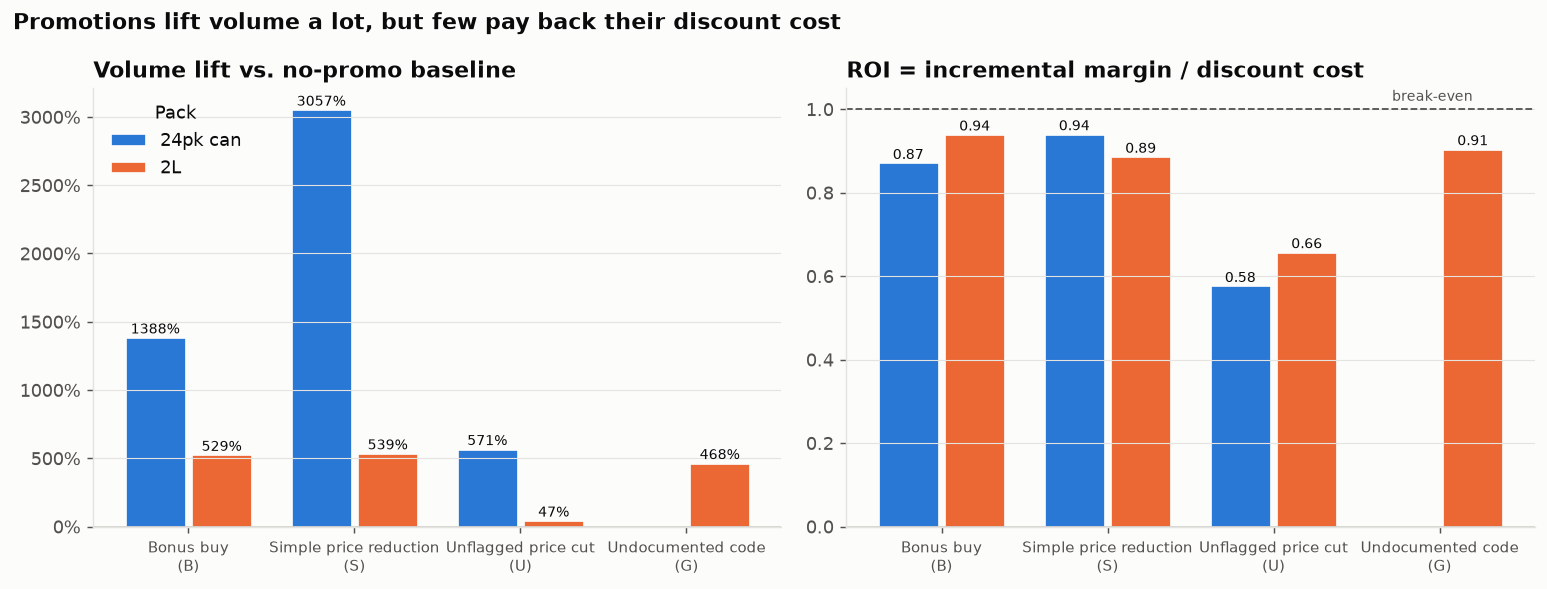

In [3]:
Image(filename=str(figure("promo_lift_roi_by_type.png")))

In [4]:
pd.read_csv(results("promo_by_depth.csv"))[["pack", "depth_bucket", "promo_weeks", "avg_discount", "lift_pct", "roi", "discount_investment", "net_margin_impact"]]

,pack,depth_bucket,promo_weeks,avg_discount,lift_pct,roi,discount_investment,net_margin_impact
0,24pk can,0-10%,2941,0.050,0.918,0.329,5.084e+04,-3.410e+04
1,24pk can,10-20%,7896,0.165,17.724,1.308,3.512e+06,1.082e+06
2,24pk can,20-30%,2919,0.261,19.982,0.909,2.231e+06,-2.040e+05
3,24pk can,30%+,5957,0.391,32.222,0.725,8.437e+06,-2.322e+06
4,2L,0-10%,3511,0.047,0.345,1.737,3.245e+04,2.391e+04
5,2L,10-20%,2802,0.152,1.654,1.393,1.976e+05,7.777e+04
6,2L,20-30%,3213,0.256,3.882,1.256,5.571e+05,1.428e+05
7,2L,30%+,10139,0.411,7.094,0.834,4.539e+06,-7.525e+05


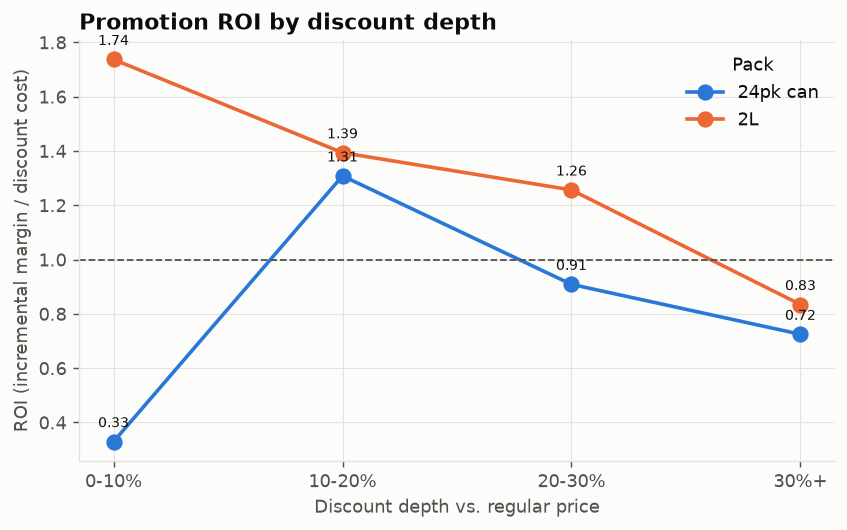

In [5]:
Image(filename=str(figure("promo_roi_by_depth.png")))

**So what:** Promotions move a lot of volume, but on average they do not pay back the margin
given away. The pattern by depth is clear: **10-20% discounts are margin-accretive (ROI above 1),
while 30%+ discounts lose money** -- and that is where about two-thirds of the discount money is
spent. Price cuts that are not tagged as a merchandised promotion (no bonus-buy / sale code) lift
volume far less than tagged ones and have the worst ROI (about 0.6).

## Ranking

In [6]:
Markdown(results("promo_ranking.md").read_text())

# Promotion ranking by ROI

_Generated by `beverage_demand.promo.analysis`. Out-of-sample backtest period (weeks 328-399); promotion types with at least 50 promoted store-weeks and an average discount of at least 5%; `lift` = volume vs. the no-promo baseline; `net` = gross-margin change vs. not promoting._

## Top 10

| promotion                                                       |   promo_weeks | lift   |   ROI | net      |
|:----------------------------------------------------------------|--------------:|:-------|------:|:---------|
| Private Label 24pk can - Bonus buy (B), 0-10% off               |           221 | +237%  |  4.4  | $1,669   |
| Pepsi 24pk can - Simple price reduction (S), 10-20% off         |           701 | +3387% |  2.02 | $973,552 |
| Private Label 24pk can - Simple price reduction (S), 10-20% off |           312 | +2939% |  2    | $29,500  |
| Diet Pepsi 24pk can - Simple price reduction (S), 10-20% off    |           704 | +2114% |  1.9  | $327,801 |
| Private Label 2L - Bonus buy (B), 10-20% off                    |            71 | +101%  |  1.83 | $3,271   |
| Private Label 24pk can - Unflagged price cut (U), 0-10% off     |           158 | +57%   |  1.73 | $248     |
| Pepsi 2L - Simple price reduction (S), 10-20% off               |           232 | +181%  |  1.64 | $11,826  |
| Coke 2L - Bonus buy (B), 10-20% off                             |           231 | +604%  |  1.59 | $31,351  |
| Diet Pepsi 2L - Simple price reduction (S), 10-20% off          |           237 | +150%  |  1.58 | $5,710   |
| Pepsi 2L - Bonus buy (B), 20-30% off                            |           274 | +564%  |  1.53 | $38,341  |

## Bottom 10

| promotion                                                    |   promo_weeks | lift   |   ROI | net     |
|:-------------------------------------------------------------|--------------:|:-------|------:|:--------|
| Diet Pepsi 2L - Bonus buy (B), 0-10% off                     |            78 | +1%    |  0.06 | $-444   |
| Private Label 24pk can - Unflagged price cut (U), 10-20% off |           254 | +2%    |  0.05 | $-382   |
| Coke 24pk can - Unflagged price cut (U), 0-10% off           |           146 | +6%    |  0.03 | $-2,317 |
| Diet Pepsi 2L - Unflagged price cut (U), 10-20% off          |           155 | -1%    |  0.02 | $-2,194 |
| Diet Coke 24pk can - Unflagged price cut (U), 0-10% off      |           179 | +22%   |  0.01 | $-2,423 |
| Diet Coke 2L - Unflagged price cut (U), 10-20% off           |           151 | +3%    | -0.01 | $-3,465 |
| Diet Pepsi 2L - Unflagged price cut (U), 0-10% off           |           477 | -4%    | -0.1  | $-3,646 |
| Diet Coke 2L - Unflagged price cut (U), 0-10% off            |           343 | -0%    | -0.13 | $-4,353 |
| Pepsi 24pk can - Bonus buy (B), 0-10% off                    |           155 | +237%  | -0.17 | $-8,771 |
| Private Label 24pk can - Unflagged price cut (U), 20-30% off |           131 | -51%   | -1.37 | $-385   |


## Post-promotion dip and cannibalisation

In [7]:
pd.read_csv(results("promo_by_series.csv"))[["series", "avg_discount", "lift_pct", "roi", "avg_competitor_volume_change_pct", "competitors_measured"]]

,series,avg_discount,lift_pct,roi,avg_competitor_volume_change_pct,competitors_measured
0,7Up | 24pk can,0.264,41.488,0.853,-0.086,5
1,7Up | 2L,0.282,3.575,0.973,-0.039,5
2,Coke | 24pk can,0.232,16.911,0.748,-0.167,4
3,Coke | 2L,0.284,4.720,0.861,-0.062,5
4,Diet Coke | 24pk can,0.232,14.483,0.720,0.038,3
5,Diet Coke | 2L,0.286,3.599,0.816,0.009,5
6,Diet Pepsi | 24pk can,0.220,15.125,0.991,NaN,0
7,Diet Pepsi | 2L,0.275,4.286,0.923,NaN,0
8,Pepsi | 24pk can,0.219,21.118,1.051,-0.030,4
9,Pepsi | 2L,0.282,5.363,0.985,-0.051,4


**So what:** After a national-brand 24-pack promotion, volume dips by roughly 8-18% the following
week (shoppers stocked up; see `promo_effects.csv`); 2-litre dips are small, and private-label
24-packs show no dip. Most brands' promotions also take volume from competitors in the same pack
-- up to about 17% of competitors' volume for Coke 24-packs -- so part of the lift is brand
switching, not new category demand.